# Clearview Properties — Residential Price Analysis

**Technical notebook.** It documents the whole analysis end to end for the Clearview Properties brief: data quality review, exploratory analysis, modeling, and the evidence behind each decision.

The client's questions:

| # | Question |
|---|---|
| Q1 | Given a property's characteristics, what is a reasonable **price range** to list it at? |
| Q2 | Which characteristics have the **largest impact on sale price**, split into owner-modifiable vs structural/location? |
| Q3 | Among the modifiable characteristics, which improvements are a **profitable investment**? |
| Q4 | Is there a clear **market segmentation**, i.e. groups of properties that behave differently? |

## Contents
0. Setup and reproducibility
1. Data quality audit and cleaning
2. Exploratory data analysis
3. Q1 — Price range model
4. Q2 — Price drivers
5. Q3 — Improvement return on investment
6. Q4 — Market segmentation
7. Conclusions, limitations and next steps

## Use of AI tools
As the brief requires: Claude (Anthropic), through Claude Code, was used as a pair-programming assistant to set up the environment, write code and propose methodological alternatives. The methodological decisions at each phase were discussed and made by the author, and the reasoning is documented in the markdown cells.

## 0. Setup and reproducibility

All randomness in this notebook comes from one constant, `SEED`. It is passed as `random_state` to every split, cross-validation splitter, model, clustering algorithm and bootstrap. The environment is pinned with `uv.lock`; see the README for setup instructions.

In [1]:
import os
import random
import re
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import statsmodels.api as sm

# --- Reproducibility -------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)              # legacy global state, for libraries that still use it
RNG = np.random.default_rng(SEED) # preferred generator for our own sampling/bootstrap
# Inherited by any worker subprocesses (e.g. joblib). It cannot change hashing in the
# already-running kernel, and none of our results depend on that.
os.environ["PYTHONHASHSEED"] = str(SEED)

# --- Paths (resolved from the project root, so it runs from any working directory) ---
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA_DIR = ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
FIG_DIR = ROOT / "main" / "figures"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# --- Display and chart defaults ----------------------------------------------
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
# Colorblind-safe categorical slots (validated reference palette; max 3 hues per chart),
# plus a neutral gray for context marks and recessive text/grid tones.
COLORS = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "gray": "#9a9993",
          "text": "#0b0b0b", "text2": "#52514e", "grid": "#e4e3df", "surface": "#fcfcfb"}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.facecolor": COLORS["surface"], "axes.facecolor": COLORS["surface"],
    "savefig.facecolor": COLORS["surface"], "axes.edgecolor": COLORS["grid"],
    "axes.labelcolor": COLORS["text2"], "axes.titlecolor": COLORS["text"],
    "xtick.color": COLORS["text2"], "ytick.color": COLORS["text2"],
    "grid.color": COLORS["grid"], "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})
USD = mticker.FuncFormatter(lambda v, _: f"${v / 1000:,.0f}k")


def save_fig(fig, name):
    """Export a figure to main/figures/ (used later for the client deck)."""
    fig.savefig(FIG_DIR / f"{name}.png")


print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")
print(f"Project root: {ROOT}")

Python 3.12.14 | pandas 3.1.1 | numpy 2.5.5 | scikit-learn 1.9.1 | matplotlib 3.11.2
Project root: C:\Users\danio\Documents\EAFIT_Maestria_CienciasIng\Clases 2026-02\Aprendizaje Automático\proyecto-final-ml


### Raw data, loaded as delivered

The raw file is never modified. Every cleaning step in Section 1 is applied in code to a copy.

`keep_default_na=False` makes pandas read the text exactly as written: only empty cells count as missing. Without it, pandas would silently turn codes such as `"NA"` or `"N/A"` into missing values, hiding part of the quality problem we need to measure.

In [2]:
raw = pd.read_csv(DATA_DIR / "Data.csv", keep_default_na=False, na_values=[""])
print(f"Raw shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

Raw shape: 2,963 rows x 82 columns


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,2693,903454020.0,30.0,RM,50.0,9000,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,IDOTRR,Norm,Norm,1Fam,1Story,5.0,4.0,1919.0,1950.0,Gable,CompShg,Wd Sdng,Wd Sdng,NaN,0.0,TA,TA,BrkTil,TA,TA,No,Unf,0.0,Unf,0.0,610.0,610.0,GasA,Ex,N,FuseA,819.0,0.0,0.0,819.0,0.0,0.0,1.0,0.0,2.0,1.0,Gd,4.0,Typ,0.0,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,N,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,9.0,2006.0,WD,Abnorml,72000
1,252,906385010.0,20.0,RL,94.0,10402,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,CollgCr,Norm,Norm,1Fam,1Story,7.0,5.0,2009.0,2009.0,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,Unf,0.0,Unf,0.0,1226.0,1226.0,GasA,Ex,Y,SBrkr,1226.0,0.0,0.0,1226.0,0.0,0.0,2.0,0.0,3.0,1.0,Gd,6.0,Typ,0.0,NaN,Attchd,2009.0,RFn,3.0,740.0,TA,TA,Y,0.0,36.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,5.0,2010.0,WD,Normal,198900
2,2146,907252020.0,60.0,RL,NaN,9375,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,8.0,5.0,2002.0,2002.0,Gable,CompShg,VinylSd,VinylSd,BrkFace,149.0,Gd,TA,PConc,Gd,TA,No,Unf,0.0,Unf,0.0,1284.0,1284.0,GasA,Ex,Y,SBrkr,1284.0,885.0,0.0,2169.0,0.0,0.0,2.0,1.0,3.0,1.0,Gd,7.0,Typ,1.0,Gd,Attchd,2002.0,RFn,2.0,647.0,TA,TA,Y,192.0,87.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,8.0,2007.0,WD,Normal,228500
3,2480,531451290.0,60.0,RL,70.0,9370,Pave,NaN,IR2,Lvl,AllPub,Inside,Gtl,SawyerW,Norm,Norm,1Fam,2Story,6.0,5.0,1992.0,1993.0,Gable,CompShg,HdBoard,HdBoard,NaN,0.0,Gd,TA,PConc,Gd,TA,No,ALQ,758.0,Unf,0.0,78.0,836.0,GasA,Ex,Y,SBrkr,844.0,887.0,0.0,1731.0,1.0,0.0,2.0,1.0,3.0,1.0,Gd,7.0,Typ,0.0,NaN,Attchd,1992.0,RFn,2.0,462.0,TA,TA,Y,307.0,85.0,0.0,0.0,224.0,0.0,NaN,NaN,Othr,3000.0,10.0,2006.0,WD,Family,248500
4,316,916386010.0,20.0,RL,88.0,11896,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Timber,Norm,Norm,1Fam,1Story,7.0,5.0,2008.0,2008.0,Gable,CompShg,VinylSd,VinylSd,Stone,60.0,Gd,TA,PConc,Gd,TA,No,GLQ,78.0,Unf,0.0,1258.0,1336.0,GasA,Ex,Y,SBrkr,1346.0,0.0,0.0,NaN,1.0,0.0,2.0,0.0,3.0,1.0,Gd,6.0,Typ,1.0,TA,Attchd,2008.0,Fin,3.0,660.0,TA,TA,Y,100.0,48.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,5.0,2010.0,WD,Normal,220000


## 1. Data quality audit and cleaning

The brief warns that the data comes "as the client handed it over". The approach:

1. **Audit:** run a fixed set of checks against the data dictionary and basic logic, and count the rows affected.
2. **Repair** in a fixed order. Each step records what it changed in a **data quality log**.
3. **Re-audit:** run the same checks on the cleaned data to verify that the problems are gone.
4. Define the **analysis sample**: which sales the price models learn from.

Agreed principles:
- **Never invent a sale price.** Rows with an invalid target are removed, not repaired.
- **Repair a corrupted value only when the same row holds direct evidence** for the correct value. Otherwise mark it as missing.
- **Leave real gaps for the imputer**, which is fitted inside the model pipeline on training data only, so no information leaks from the test set.

### 1.1 Valid codes, read from the data dictionary

The dictionary states that every listed code appears in the file exactly as written. We parse it, so the valid codes come from the client's own documentation rather than from hard-coded lists.

In [3]:
def parse_dictionary(path, columns):
    """Return {column: set of valid codes} for every coded column in the data dictionary."""
    codes, current = {}, None
    for line in path.read_text(encoding="utf-8").splitlines():
        if line.startswith("NOTES ON MISSING"):          # end of the variable section
            break
        header = re.match(r"^(\S.*?)\s{2,}\S", line)       # "Column Name   description"
        if header and header.group(1) in columns:
            current = header.group(1)
            continue
        entry = re.match(r"^\s{10,}(\S.*?)\s{2,}\S", line) # "      CODE   meaning"
        if current and entry:
            codes.setdefault(current, set()).add(entry.group(1))
        elif current == "Neighborhood" and "," in line:   # neighborhoods are listed inline
            codes[current] = {c.strip() for c in line.split(",")}
    return codes


VALID_CODES = parse_dictionary(DATA_DIR / "Data_Dictionary.txt", raw.columns)
CODED_TEXT_COLS = [c for c in VALID_CODES if c != "MS SubClass"]   # MS SubClass is a numeric code
print(f"{len(VALID_CODES)} coded columns parsed, e.g.:")
for col in ["MS Zoning", "Central Air", "Sale Type"]:
    print(f"  {col}: {sorted(VALID_CODES[col])}")
print(f"  Neighborhood: {len(VALID_CODES['Neighborhood'])} codes")

44 coded columns parsed, e.g.:
  MS Zoning: ['A (agr)', 'C (all)', 'FV', 'I (all)', 'RH', 'RL', 'RM']
  Central Air: ['N', 'Y']
  Sale Type: ['COD', 'CWD', 'Con', 'ConLD', 'ConLI', 'ConLw', 'New', 'Oth', 'VWD', 'WD']
  Neighborhood: 28 codes


### 1.2 Audit of the raw file

One function holds every check. It runs on the raw data now and on the cleaned data at the end of this section, so the same code shows both the problem and its fix.

In [4]:
ABSENT = "Absent"   # label used later for "this feature does not exist" (no pool, no garage...)


def as_code(s):
    """Text view of a coded column (numeric codes such as MS SubClass become '30', '120')."""
    if pd.api.types.is_numeric_dtype(s):
        return s.astype("Int64").astype("string")
    return s.astype("string")


def audit(df):
    """Count the rows affected by each known class of data problem."""
    price = pd.to_numeric(df["SalePrice"], errors="coerce")
    lot_txt = df["Lot Area"].astype("string")
    if pd.api.types.is_numeric_dtype(df["Lot Area"]):
        lot, lot_units, lot_decimal = df["Lot Area"], pd.Series(False, index=df.index), (df["Lot Area"] % 1).fillna(0) != 0
    else:
        lot = pd.to_numeric(lot_txt.str.replace(r"[^\d.]", "", regex=True), errors="coerce")
        lot_units, lot_decimal = lot_txt.str.contains(r"[A-Za-z]", na=False), lot_txt.str.contains(r"\.", na=False)
    ppsf = price / df["Gr Liv Area"]

    label_space = pd.Series(False, index=df.index)   # fixed by removing surrounding spaces
    label_other = pd.Series(False, index=df.index)   # wrong case, synonym or placeholder
    for col, valid in VALID_CODES.items():
        s, ok = as_code(df[col]), list(valid | {ABSENT})
        bad = s.notna() & ~s.isin(ok)
        spaces = bad & s.str.strip().isin(ok)
        label_space |= spaces.fillna(False)
        label_other |= (bad & ~spaces).fillna(False)

    years = df[["Year Built", "Year Remod/Add", "Garage Yr Blt"]]
    components = df["1st Flr SF"] + df["2nd Flr SF"] + df["Low Qual Fin SF"]
    checks = {
        "Empty rows (>90% of fields missing)": df.isna().mean(axis=1) > 0.9,
        "Exact duplicate rows (ignoring Order)": df.drop(columns="Order").duplicated(),
        "Extra rows for an already-seen PID": df["PID"].notna() & df["PID"].duplicated(),
        "Duplicated Order id": df["Order"].duplicated(),
        "SalePrice stored as text ($, commas)": df["SalePrice"].notna() & price.isna(),
        "SalePrice missing": df["SalePrice"].isna(),
        "SalePrice zero or negative": price <= 0,
        "SalePrice implausible (>10x median $/sqft)": ppsf > 10 * ppsf.median(),
        "Lot Area stored with units text": lot_units,
        "Lot Area with decimals (square meters)": lot_decimal,
        "Lot Area equal to zero": lot == 0,
        "Year later than 2010 (after study period)": (years > 2010).any(axis=1),
        "Remodel year earlier than build year": df["Year Remod/Add"] < df["Year Built"],
        "Sale year outside 2006-2010": ~df["Yr Sold"].between(2006, 2010) & df["Yr Sold"].notna(),
        "Category label with extra spaces": label_space,
        "Category label not in dictionary (case/synonym/placeholder)": label_other,
        "Gr Liv Area missing": df["Gr Liv Area"].isna(),
        "Gr Liv Area != 1st + 2nd + low-quality floor area": (components - df["Gr Liv Area"]).abs() > 1,
    }
    return pd.Series({name: int(mask.sum()) for name, mask in checks.items()}, name="rows")


audit_raw = audit(raw)
audit_raw.to_frame("rows affected (raw)")

,rows affected (raw)
Empty rows (>90% of fields missing),3
Exact duplicate rows (ignoring Order),18
Extra rows for an already-seen PID,30
Duplicated Order id,20
"SalePrice stored as text ($, commas)",30
SalePrice missing,23
SalePrice zero or negative,5
SalePrice implausible (>10x median $/sqft),2
Lot Area stored with units text,20
Lot Area with decimals (square meters),30


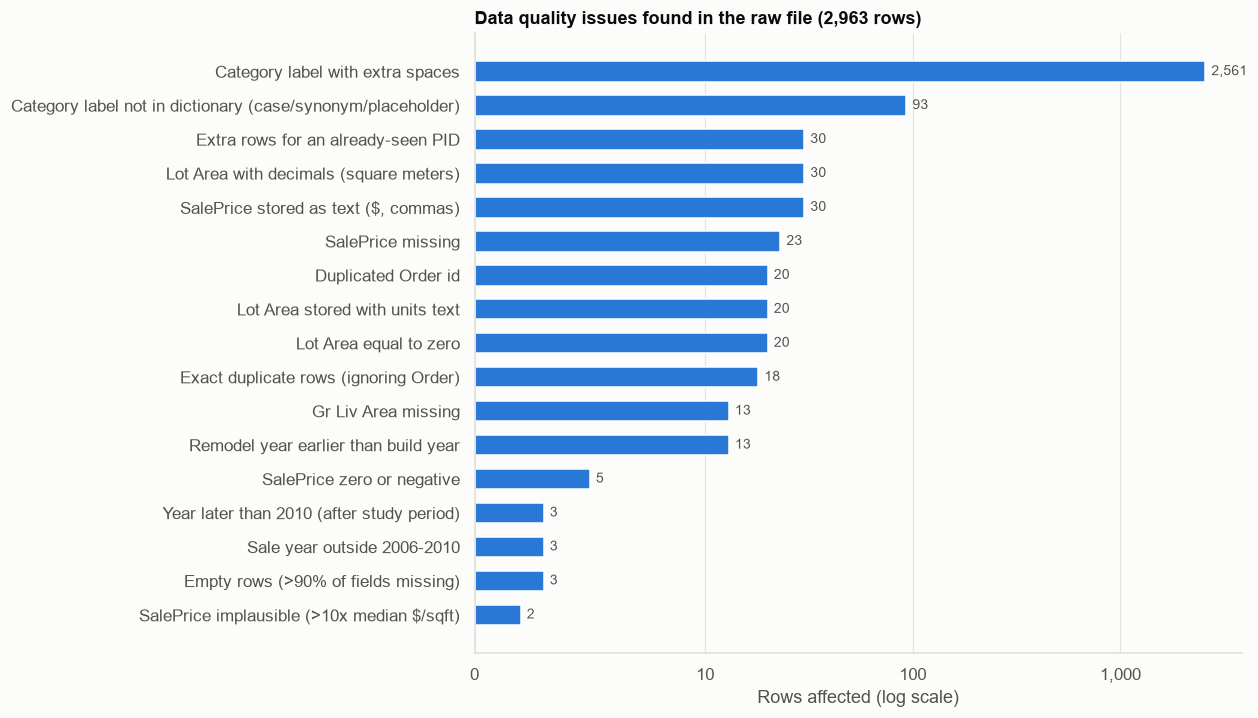

In [5]:
issues = audit_raw[audit_raw > 0].sort_values()
fig, ax = plt.subplots(figsize=(9, 0.36 * len(issues) + 1.2))
ax.barh(issues.index, issues.values, color=COLORS["blue"], height=0.6)
for y, v in enumerate(issues.values):
    ax.annotate(f"{v:,}", (v, y), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=COLORS["text2"])
ax.set_xscale("symlog", linthresh=10)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("Rows affected (log scale)")
ax.set_title(f"Data quality issues found in the raw file ({len(raw):,} rows)")
ax.grid(axis="y", visible=False)
save_fig(fig, "01_raw_data_quality_issues")
plt.show()

The structural missing values (no pool, no garage, and so on) are **not** counted as issues. The dictionary defines them as "the feature does not exist", and step 9 encodes them explicitly.

### 1.3 Repair pipeline

Each step works on a copy of the raw data and appends one or more entries to `QUALITY_LOG`: the issue, the rows affected, the action taken and the rationale.

In [6]:
QUALITY_LOG = []


def log(step, issue, rows, action, rationale):
    QUALITY_LOG.append({"step": step, "issue": issue, "rows_affected": int(rows),
                        "action": action, "rationale": rationale})


df = raw.copy()

**Step 1: Empty rows.** Three rows have no PID, no price and almost every field blank. They carry no information.

In [7]:
empty = df.isna().mean(axis=1) > 0.9
log(1, "Empty rows", empty.sum(), "Dropped", "No PID, no price, >90% of fields blank")
df = df.loc[~empty].copy()
print(f"Dropped {empty.sum()} empty rows -> {len(df):,} rows")

Dropped 3 empty rows -> 2,960 rows


**Step 2: Numbers stored as text, and wrong units.**
- `SalePrice` sometimes appears as `"$215,000"`. We strip the symbols; the value itself is correct.
- `Lot Area` sometimes appears as `"5362 sqft"`. We strip the units text.
- Some `Lot Area` values are written with a decimal point (e.g. `713.2`) while every other lot area is a whole number. These values are 10× smaller than typical lots, and one of them has a duplicate record with **7,677 sqft = 713.2 m² × 10.764**. They were recorded in **square meters**, so we convert them.
- `Lot Area = 0` is physically impossible. We set it to missing for the imputer.

In [8]:
SQM_TO_SQFT = 10.7639

# SalePrice: remove "$" and thousands separators
price_txt = df["SalePrice"].astype("string")
has_symbols = price_txt.str.contains(r"[$,]", na=False)
df["SalePrice"] = pd.to_numeric(price_txt.str.replace(r"[$,\s]", "", regex=True), errors="coerce")
log(2, "SalePrice stored as text", has_symbols.sum(), "Removed '$' and ',' and converted to number",
    "Formatting problem only; the amount is valid")

# Lot Area: units text, square meters, zeros
lot_txt = df["Lot Area"].astype("string").str.strip()
has_units = lot_txt.str.contains(r"[A-Za-z]", na=False)
in_sqm = lot_txt.str.contains(r"\.", na=False)
lot = pd.to_numeric(lot_txt.str.replace(r"[^\d.]", "", regex=True), errors="coerce")
lot_before_conversion = lot.copy()
lot = lot.where(~in_sqm, (lot * SQM_TO_SQFT).round())
zero_lot = lot == 0
df["Lot Area"] = lot.mask(zero_lot)
log(2, "Lot Area with units text ('sqft')", has_units.sum(), "Removed text, kept the number",
    "Formatting problem only")
log(2, "Lot Area recorded in square meters", in_sqm.sum(), "Multiplied by 10.764 and rounded",
    "Only decimal values in a whole-number column, ~10x below typical lots, confirmed by a duplicate record")
log(2, "Lot Area equal to zero", zero_lot.sum(), "Set to missing (imputed later in the pipeline)",
    "A lot cannot have zero area")

# Identifier-like numeric codes read as floats -> integers
df["PID"] = df["PID"].astype("Int64")
df["MS SubClass"] = df["MS SubClass"].astype("Int64")

In [9]:
# Evidence for the square-meter conversion: corrupted values vs. their neighborhood's typical lot
nbhd_median_lot = lot.where(~in_sqm).groupby(df["Neighborhood"]).median()
sqm_evidence = pd.DataFrame({
    "PID": df.loc[in_sqm, "PID"],
    "Neighborhood": df.loc[in_sqm, "Neighborhood"],
    "value as recorded": lot_before_conversion[in_sqm],
    "converted to sqft": lot[in_sqm],
    "neighborhood median (sqft)": df.loc[in_sqm, "Neighborhood"].map(nbhd_median_lot),
})
sqm_evidence["recorded / median"] = (sqm_evidence["value as recorded"] / sqm_evidence["neighborhood median (sqft)"]).round(2)
sqm_evidence["converted / median"] = (sqm_evidence["converted to sqft"] / sqm_evidence["neighborhood median (sqft)"]).round(2)
print("Median ratio to the neighborhood's typical lot -> as recorded: "
      f"{sqm_evidence['recorded / median'].median():.2f} | after conversion: {sqm_evidence['converted / median'].median():.2f}")
sqm_evidence.head(10)

Median ratio to the neighborhood's typical lot -> as recorded: 0.10 | after conversion: 1.02


,PID,Neighborhood,value as recorded,converted to sqft,neighborhood median (sqft),recorded / median,converted / median
27,533350120,Veenker,1512.4,16279.0,13165.0,0.11,1.24
45,907192030,CollgCr,830.1,8935.0,9675.0,0.09,0.92
82,905107240,Sawyer,960.1,10334.0,9402.0,0.1,1.1
246,905300020,Sawyer,947.6,10200.0,9402.0,0.1,1.08
427,527402380,NAmes,868.9,9353.0,9486.0,0.09,0.99
460,528427020,Somerst,893.0,9612.0,8125.0,0.11,1.18
483,923277030,Mitchel,613.1,6599.0,10172.0,0.06,0.65
639,902406020,OldTown,905.8,9750.0,7830.0,0.12,1.25
664,535305160,NAmes,713.2,7677.0,9486.0,0.08,0.81
747,534251320,NWAmes,909.5,9790.0,10944.0,0.08,0.89


**Step 3: Category labels.** Labels are matched to the dictionary codes after removing surrounding spaces and ignoring case (`rl`, `Rl`, ` RL` → `RL`). Two synonyms not in the dictionary are mapped explicitly: `paved` → `Pave` and `yes` → `Y`. Placeholders that mean "unknown" (`NA`, `N/A`, `??`, `unknown`) become missing; step 8 recovers them. The cell **asserts** that nothing else is left unmatched, so no label is dropped silently.

In [10]:
SYNONYMS = {"Street": {"paved": "Pave"}, "Central Air": {"yes": "Y"}}
PLACEHOLDERS = {"na", "n/a", "??", "unknown"}

changes = []
for col in CODED_TEXT_COLS:
    original = df[col].astype("string")
    lookup = {code.lower(): code for code in VALID_CODES[col]} | SYNONYMS.get(col, {})
    key = original.str.strip().str.lower()
    mapped = key.map(lookup)
    unmatched = original.notna() & mapped.isna()
    assert key[unmatched].isin(PLACEHOLDERS).all(), f"{col}: unexpected labels {set(original[unmatched])}"
    changed = original.notna() & (original != mapped).fillna(True)
    if changed.any():
        changes.append(pd.DataFrame({"column": col, "original": original[changed],
                                     "cleaned": mapped[changed].fillna("<missing>")}))
    df[col] = mapped.astype(object).where(mapped.notna(), np.nan)

label_changes = pd.concat(changes)
summary = (label_changes.assign(original=label_changes["original"].map(repr))
           .groupby(["column", "original", "cleaned"]).size().rename("rows").reset_index())
log(3, "Category labels with extra spaces / wrong case / synonyms", label_changes.index.nunique(),
    "Mapped to the dictionary code", "Same category written differently; would otherwise split one category into several")
summary

,column,original,cleaned,rows
0,Central Air,'YES',Y,8
1,Central Air,'Yes',Y,8
2,Central Air,'y',Y,7
3,Central Air,'yes',Y,8
4,MS Zoning,' RL',RL,10
5,MS Zoning,'RL ',RL,10
6,MS Zoning,'Rl',RL,10
7,MS Zoning,'rl',RL,10
8,Neighborhood,'??',<missing>,4
9,Neighborhood,'N/A',<missing>,4


**Step 4: Duplicates.** Once formats are normalized (step 2), more rows become exact copies: `"$330,000"` and `330000` now match. Exact copies are dropped first. Then we look at PIDs that still appear more than once. A PID identifies a property, and a property could legitimately sell twice, so we check whether the repeated rows describe the **same sale** (same month and year).

In [11]:
exact_dup = df.drop(columns="Order").duplicated()
log(4, "Exact duplicate rows", exact_dup.sum(), "Dropped (kept first)", "Same sale recorded twice")
df = df.loc[~exact_dup].copy()

repeated = df[df["PID"].duplicated(keep=False)].sort_values(["PID", "Order"])
same_sale = repeated.groupby("PID")[["Yr Sold", "Mo Sold"]].nunique().max(axis=1).eq(1)
print(f"PIDs still repeated: {repeated['PID'].nunique()} | all repeats share the same sale month: {same_sale.all()}")


def describe_differences(group):
    cols = [c for c in group.columns.drop("Order") if group[c].astype("string").nunique(dropna=False) > 1]
    return "; ".join(f"{c}: " + " vs ".join(group[c].astype("string").fillna("NaN")) for c in cols)


near_dup_table = repeated.groupby("PID").apply(describe_differences, include_groups=False).rename("differences").to_frame()
near_dup_table

PIDs still repeated: 11 | all repeats share the same sale month: True


,differences
PID,
531367010,Lot Area: 11024.0 vs 11023.0; SalePrice: 18680...
533208020,Garage Yr Blt: 2006.0 vs 1987.0
533213120,Lot Area: 2281.0 vs 2280.0; SalePrice: 173000 ...
533221040,Lot Area: 2999.0 vs 2998.0; SalePrice: 180100 ...
535353060,Lot Area: 9532.0 vs 9533.0; SalePrice: 102800 ...
902205010,Lot Area: 5926.0 vs 5925.0; SalePrice: 45100 v...
903231090,Lot Area: 6240.0 vs 6239.0; SalePrice: 126000 ...
903454100,Lot Area: 6875.0 vs 6876.0; SalePrice: 140900 ...
907202160,Lot Area: 10971.0 vs 10970.0; SalePrice: NaN v...


Every repeated PID is the same sale recorded twice, with tiny differences: about $100 in price and 1 sqft in lot area, or a missing value in one copy. These differences are below 0.1% and do not change any conclusion. We keep **one record per sale**: the copy with a valid price and the fewest missing values, and on a tie the lowest `Order` (the first recorded).

In [12]:
ranked = (df.assign(_price_ok=df["SalePrice"].gt(0), _n_missing=df.isna().sum(axis=1))
            .sort_values(["PID", "_price_ok", "_n_missing", "Order"], ascending=[True, False, True, True]))
keep = ranked.drop_duplicates("PID").index
n_near = len(df) - len(keep)
log(4, "Same sale recorded twice with small differences (same PID & sale month)", n_near,
    "Kept one record: valid price, fewest missing values, then first Order",
    "Differences <0.1% (about $100 / 1 sqft), so the choice does not affect results")
df = df.loc[df.index.isin(keep)].copy()
assert df["PID"].is_unique and df["Order"].is_unique
print(f"Removed {exact_dup.sum()} exact + {n_near} near duplicates -> {len(df):,} rows; PID and Order are now unique")

Removed 19 exact + 11 near duplicates -> 2,930 rows; PID and Order are now unique


**Step 5: Rebuild missing `Gr Liv Area`.** Above-ground living area is, by definition, 1st floor + 2nd floor + low-quality finished area. This identity holds exactly in **every** complete row (audit check above: 0 mismatches), so the missing values can be computed rather than guessed.

In [13]:
components = df["1st Flr SF"] + df["2nd Flr SF"] + df["Low Qual Fin SF"]
rebuild = df["Gr Liv Area"].isna() & components.notna()
df.loc[rebuild, "Gr Liv Area"] = components[rebuild]
log(5, "Gr Liv Area missing", rebuild.sum(), "Computed as 1st + 2nd + low-quality floor area",
    "Exact identity, verified with 0 mismatches in complete rows")
print(f"Rebuilt {rebuild.sum()} values; still missing: {df['Gr Liv Area'].isna().sum()}")

Rebuilt 10 values; still missing: 0


**Step 6: Invalid sale prices (agreed: drop).** The sale price is what the models learn from, so we do not invent it. There are three kinds of invalid price:
- **missing**;
- **zero or negative**: plausible amounts with a flipped sign, but we cannot verify that;
- **implausible**: price per sqft above 10× the median. The two cases are placeholder-looking values ($12.5M and $9,999,999) on ordinary houses, more than 60× the typical $/sqft.

In [14]:
ppsf = df["SalePrice"] / df["Gr Liv Area"]
target_issue = pd.Series(pd.NA, index=df.index, dtype="string")
target_issue[df["SalePrice"].isna()] = "missing"
target_issue[df["SalePrice"] <= 0] = "zero or negative"
target_issue[ppsf > 10 * ppsf.median()] = "implausible (>10x median $/sqft)"
bad_target = target_issue.notna()

display(df.loc[bad_target & target_issue.ne("missing"),
               ["PID", "Neighborhood", "Gr Liv Area", "Overall Qual", "SalePrice"]]
        .assign(price_per_sqft=ppsf.round(0), issue=target_issue))
print(f"Median $/sqft of valid sales: {ppsf[~bad_target].median():.0f}")
for kind, n in target_issue.value_counts().items():
    log(6, f"SalePrice {kind}", n, "Dropped", "The target is never invented; see the agreed decision")
df = df.loc[~bad_target].copy()
print(f"Dropped {bad_target.sum()} rows with an invalid price -> {len(df):,} rows")

,PID,Neighborhood,Gr Liv Area,Overall Qual,SalePrice,price_per_sqft,issue
300,914476520,Mitchel,1560.0,7.0,12500000,8013.0,implausible (>10x median $/sqft)
660,907135180,CollgCr,990.0,4.0,-129000,-130.0,zero or negative
1360,911204100,IDOTRR,952.0,4.0,9999999,10504.0,implausible (>10x median $/sqft)
1629,903427090,OldTown,1666.0,8.0,-62500,-38.0,zero or negative
1710,910200080,IDOTRR,919.0,6.0,-105000,-114.0,zero or negative
2289,527450460,BrDale,1030.0,6.0,-167900,-163.0,zero or negative
2361,908128100,Edwards,1724.0,7.0,-138400,-80.0,zero or negative


Median $/sqft of valid sales: 120
Dropped 26 rows with an invalid price -> 2,904 rows


**Step 7: Impossible years (agreed: rule-based repair using evidence in the same row).**
- **Sale year outside 2006–2010.** The 3 rows dated 2005 are new homes built in 2006–2007, so they would be "sold before being built", and they fall outside the period the dictionary describes. The true year cannot be recovered, so the rows are dropped.
- **Build year after 2010.** Replaced with the garage year when that is plausible, otherwise the remodel year.
- **Garage year after 2010.** Replaced with the house's build year.
- **Remodel year earlier than build year.** The dictionary says *remodel = build year when there was no remodel*, so remodel is set to the build year ("not remodeled").

New homes whose build or remodel year is one year *after* the sale year are **kept**: these are sales of homes still under construction (`Sale Condition = Partial`).

In [15]:
year_cols = ["Year Built", "Year Remod/Add", "Garage Yr Blt", "Yr Sold", "Sale Condition"]

bad_sale_year = ~df["Yr Sold"].between(2006, 2010)
display(df.loc[bad_sale_year, year_cols])
log(7, "Sale year outside 2006-2010", bad_sale_year.sum(), "Dropped",
    "New homes 'sold before being built' and outside the documented period; true year unrecoverable")
df = df.loc[~bad_sale_year].copy()

bad_built = df["Year Built"] > 2010
before = df.loc[bad_built, year_cols].copy()
garage_ok = df["Garage Yr Blt"].between(1800, 2010)
df.loc[bad_built, "Year Built"] = np.where(garage_ok[bad_built], df.loc[bad_built, "Garage Yr Blt"],
                                           df.loc[bad_built, "Year Remod/Add"])
log(7, "Build year after 2010", bad_built.sum(), "Replaced with garage year (or remodel year)",
    "Same-row evidence: garage and remodel years agree with each other")

bad_garage = df["Garage Yr Blt"] > 2010
before = pd.concat([before, df.loc[bad_garage, year_cols]])
df.loc[bad_garage, "Garage Yr Blt"] = df.loc[bad_garage, "Year Built"]
log(7, "Garage year after 2010", bad_garage.sum(), "Replaced with build year",
    "Garage built with the house (new home); 2207 is a typo")

remod_before_built = df["Year Remod/Add"] < df["Year Built"]
df.loc[remod_before_built, "Year Remod/Add"] = df.loc[remod_before_built, "Year Built"]
log(7, "Remodel year earlier than build year", remod_before_built.sum(), "Set remodel year = build year",
    "Dictionary rule: equal to build year when there was no remodel")

print("Rows with an impossible build/garage year - before and after:")
display(before.join(df[["Year Built", "Garage Yr Blt"]].add_suffix(" (repaired)")))
built_after_sale = df["Year Built"] > df["Yr Sold"]
assert df.loc[built_after_sale, "Sale Condition"].eq("Partial").all()   # all are sales of homes under construction
print(f"Remodel years corrected: {remod_before_built.sum()} | "
      f"homes built after the sale year (kept, all 'Partial' = under construction): {built_after_sale.sum()}")

,Year Built,Year Remod/Add,Garage Yr Blt,Yr Sold,Sale Condition
629,2006.0,2006.0,2006.0,2005.0,Partial
1800,2006.0,2007.0,2006.0,2005.0,Partial
2181,2007.0,2008.0,2008.0,2005.0,Partial


Rows with an impossible build/garage year - before and after:


,Year Built,Year Remod/Add,Garage Yr Blt,Yr Sold,Sale Condition,Year Built (repaired),Garage Yr Blt (repaired)
510,2099.0,2006.0,2006.0,2007.0,Partial,2006.0,2006.0
1697,2050.0,1968.0,1968.0,2007.0,Normal,1968.0,1968.0
2864,2006.0,2007.0,2207.0,2007.0,Partial,2006.0,2006.0


Remodel years corrected: 11 | homes built after the sale year (kept, all 'Partial' = under construction): 3


**Step 8: Unknown neighborhoods (agreed: nearest parcel ID).** A PID is a tax-map parcel number, so parcels with close numbers sit close together. Before using this, we **test it**: for every property with a known neighborhood, we hide its label and predict it from the nearest other PID (leave-one-out validation).

In [16]:
def nearest_pid_label(query, ref_pids, ref_labels):
    """Label of the reference parcel whose PID is numerically closest to each query PID."""
    order = np.argsort(ref_pids)
    p, lab = ref_pids[order], ref_labels[order]
    pos = np.searchsorted(p, query)
    left, right = np.clip(pos - 1, 0, len(p) - 1), np.clip(pos, 0, len(p) - 1)
    use_left = np.abs(query - p[left]) <= np.abs(p[right] - query)
    return np.where(use_left, lab[left], lab[right])


def nearest_pid_loo_accuracy(pids, labels):
    """Leave-one-out: predict each known label from its nearest *other* parcel."""
    order = np.argsort(pids)
    p, lab = pids[order], labels[order]
    d_prev, d_next = np.r_[np.inf, np.diff(p)], np.r_[np.diff(p), np.inf]
    prev_lab, next_lab = np.r_[lab[:1], lab[:-1]], np.r_[lab[1:], lab[-1:]]
    return (np.where(d_prev <= d_next, prev_lab, next_lab) == lab).mean()


known = df["Neighborhood"].notna()
ref_pids = df.loc[known, "PID"].to_numpy(dtype="int64")
ref_labels = df.loc[known, "Neighborhood"].to_numpy(dtype=object)
loo_acc = nearest_pid_loo_accuracy(ref_pids, ref_labels)
majority_acc = df.loc[known, "Neighborhood"].value_counts(normalize=True).iloc[0]
print(f"Leave-one-out accuracy, nearest PID: {loo_acc:.1%}  (baseline 'most common neighborhood': {majority_acc:.1%})")

unknown = ~known
df.loc[unknown, "Neighborhood"] = nearest_pid_label(df.loc[unknown, "PID"].to_numpy(dtype="int64"), ref_pids, ref_labels)
log(8, "Neighborhood unknown (NA, N/A, ??, unknown)", unknown.sum(), "Assigned the neighborhood of the nearest parcel ID",
    f"PIDs are spatial; validated at {loo_acc:.1%} leave-one-out accuracy")
df.loc[unknown, ["PID", "Neighborhood"]].value_counts("Neighborhood").rename("rows recovered").to_frame().T

Leave-one-out accuracy, nearest PID: 98.8%  (baseline 'most common neighborhood': 15.2%)


Neighborhood,NAmes,BrkSide,Sawyer,Edwards,Gilbert,Timber,IDOTRR,Blmngtn,OldTown,SawyerW,Crawfor
rows recovered,4,2,2,2,2,2,1,1,1,1,1


**Step 9: Features that do not exist.** The dictionary says that for pools, garages, basements, fireplaces, fences, alleys, masonry veneer and miscellaneous features, NaN means "the house does not have it". We encode that explicitly as `"Absent"`, and set the matching areas and counts to 0, so these values are never mistaken for real gaps. We apply this only when the row is consistent: a missing garage *finish* on a house that *has* a garage is a real gap and is left for the imputer. `Garage Yr Blt` stays empty when there is no garage, because no year is meaningful there.

In [17]:
STRUCTURAL = {
    # group: (rows where the feature is absent, text columns -> "Absent", numeric columns -> 0)
    "basement": (df["Bsmt Qual"].isna() & df["Total Bsmt SF"].fillna(0).eq(0),
                 ["Bsmt Qual", "Bsmt Cond", "Bsmt Exposure", "BsmtFin Type 1", "BsmtFin Type 2"],
                 ["BsmtFin SF 1", "BsmtFin SF 2", "Bsmt Unf SF", "Total Bsmt SF", "Bsmt Full Bath", "Bsmt Half Bath"]),
    "garage": (df["Garage Type"].isna() & df["Garage Area"].fillna(0).eq(0),
               ["Garage Type", "Garage Finish", "Garage Qual", "Garage Cond"], ["Garage Cars", "Garage Area"]),
    "fireplace": (df["Fireplace Qu"].isna() & df["Fireplaces"].eq(0), ["Fireplace Qu"], []),
    "pool": (df["Pool QC"].isna() & df["Pool Area"].eq(0), ["Pool QC"], []),
    "masonry veneer": (df["Mas Vnr Type"].isna() & df["Mas Vnr Area"].eq(0), ["Mas Vnr Type"], []),
    "alley": (df["Alley"].isna(), ["Alley"], []),
    "fence": (df["Fence"].isna(), ["Fence"], []),
    "misc feature": (df["Misc Feature"].isna() & df["Misc Val"].eq(0), ["Misc Feature"], []),
}
for group, (absent, text_cols, num_cols) in STRUCTURAL.items():
    for c in text_cols:
        df.loc[absent & df[c].isna(), c] = ABSENT
    for c in num_cols:
        df.loc[absent & df[c].isna(), c] = 0
    log(9, f"No {group} (NaN by design)", absent.sum(), f"Encoded as '{ABSENT}' (areas/counts = 0)",
        "Dictionary: NaN means the feature does not exist")
print({g: int(m.sum()) for g, (m, _, _) in STRUCTURAL.items()})

{'basement': 79, 'garage': 156, 'fireplace': 1407, 'pool': 2888, 'masonry veneer': 1731, 'alley': 2706, 'fence': 2333, 'misc feature': 2796}


### 1.4 Verification: re-run the audit on the cleaned data

In [18]:
audit_clean = audit(df)
audit_compare = pd.DataFrame({"raw": audit_raw, "cleaned": audit_clean})
assert audit_clean.eq(0).all(), audit_clean[audit_clean > 0]
print(f"Rows: {len(raw):,} raw -> {len(df):,} cleaned ({len(raw) - len(df)} removed). Every check now returns 0.")
audit_compare

Rows: 2,963 raw -> 2,901 cleaned (62 removed). Every check now returns 0.


,raw,cleaned
Empty rows (>90% of fields missing),3,0
Exact duplicate rows (ignoring Order),18,0
Extra rows for an already-seen PID,30,0
Duplicated Order id,20,0
"SalePrice stored as text ($, commas)",30,0
SalePrice missing,23,0
SalePrice zero or negative,5,0
SalePrice implausible (>10x median $/sqft),2,0
Lot Area stored with units text,20,0
Lot Area with decimals (square meters),30,0


In [19]:
quality_log = pd.DataFrame(QUALITY_LOG)
quality_log.to_csv(PROCESSED_DIR / "data_quality_log.csv", index=False)
df.to_csv(PROCESSED_DIR / "clean_all_sales.csv", index=False)
quality_log

,step,issue,rows_affected,action,rationale
0,1,Empty rows,3,Dropped,"No PID, no price, >90% of fields blank"
1,2,SalePrice stored as text,30,"Removed '$' and ',' and converted to number",Formatting problem only; the amount is valid
2,2,Lot Area with units text ('sqft'),20,"Removed text, kept the number",Formatting problem only
3,2,Lot Area recorded in square meters,30,Multiplied by 10.764 and rounded,"Only decimal values in a whole-number column, ..."
4,2,Lot Area equal to zero,20,Set to missing (imputed later in the pipeline),A lot cannot have zero area
5,3,Category labels with extra spaces / wrong case...,2571,Mapped to the dictionary code,Same category written differently; would other...
6,4,Exact duplicate rows,19,Dropped (kept first),Same sale recorded twice
7,4,Same sale recorded twice with small difference...,11,"Kept one record: valid price, fewest missing v...","Differences <0.1% (about $100 / 1 sqft), so th..."
8,5,Gr Liv Area missing,10,Computed as 1st + 2nd + low-quality floor area,"Exact identity, verified with 0 mismatches in ..."
9,6,SalePrice missing,19,Dropped,The target is never invented; see the agreed d...


### 1.5 Analysis sample: which sales the price models learn from

**Agreed decision:** model **Normal** and **Partial** (new home) sales, with an `is_new_home` flag, and exclude houses above 4,000 sqft. Q3 will be re-checked on Normal sales only. The evidence follows.

**a) Non-market sales sell at a discount.** We fit a simple reference model on Normal sales only (log price ~ log living area + overall quality + build year). We then compare each sale type with the price that model expects for a comparable house. The 95% intervals come from a bootstrap of the median gap (with `RNG`, so they are reproducible).

In [20]:
ref = df.dropna(subset=["Gr Liv Area", "Overall Qual", "Year Built"]).copy()
X_ref = sm.add_constant(np.column_stack([np.log(ref["Gr Liv Area"]), ref["Overall Qual"], ref["Year Built"]]))
y_ref = np.log(ref["SalePrice"].to_numpy())
is_normal = ref["Sale Condition"].eq("Normal").to_numpy()
ref_fit = sm.OLS(y_ref[is_normal], X_ref[is_normal]).fit()
ref["gap"] = y_ref - ref_fit.predict(X_ref)


def bootstrap_median(x, n_boot=2000):
    x = np.asarray(x)
    meds = np.median(x[RNG.integers(0, len(x), size=(n_boot, len(x)))], axis=1)
    return np.percentile(meds, [2.5, 97.5])


rows = []
for cond, g in ref.groupby("Sale Condition"):
    lo, hi = bootstrap_median(g["gap"])
    rows.append({"Sale Condition": cond, "n": len(g), "median price": g["SalePrice"].median(),
                 "median $/sqft": (g["SalePrice"] / g["Gr Liv Area"]).median(),
                 "% vs comparable Normal sale": 100 * np.expm1(g["gap"].median()),
                 "95% CI low": 100 * np.expm1(lo), "95% CI high": 100 * np.expm1(hi)})
cond_effect = pd.DataFrame(rows).set_index("Sale Condition").sort_values("% vs comparable Normal sale")
print(f"Reference model on Normal sales: R² = {ref_fit.rsquared:.3f}")
cond_effect.round(1)

Reference model on Normal sales: R² = 0.816


,n,median price,median $/sqft,% vs comparable Normal sale,95% CI low,95% CI high
Sale Condition,,,,,,
AdjLand,12,110000.0,83.8,-11.2,-26.6,-1.7
Abnorml,187,129000.0,100.7,-8.1,-11.3,-5.0
Family,44,144900.0,109.9,-4.6,-11.2,2.1
Normal,2385,159000.0,119.4,0.5,-0.1,1.3
Partial,240,250000.0,149.1,4.4,1.2,6.9
Alloca,23,150909.0,86.6,4.7,-21.8,7.3


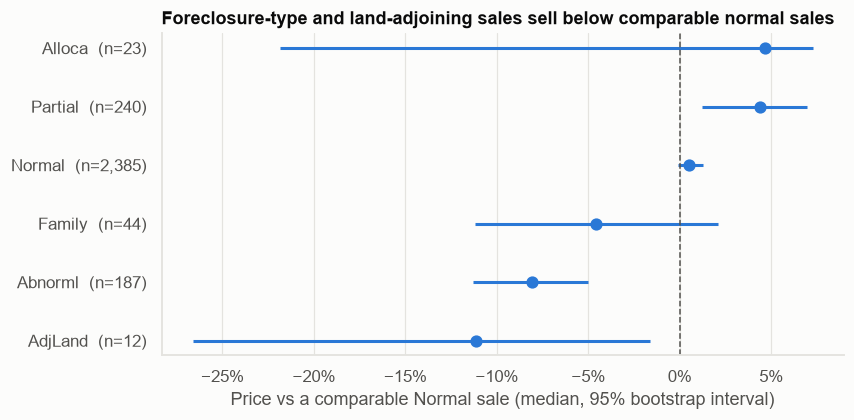

In [21]:
t = cond_effect.sort_values("% vs comparable Normal sale")
fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(t))
ax.errorbar(t["% vs comparable Normal sale"], y,
            xerr=[t["% vs comparable Normal sale"] - t["95% CI low"], t["95% CI high"] - t["% vs comparable Normal sale"]],
            fmt="o", color=COLORS["blue"], ecolor=COLORS["blue"], elinewidth=2, markersize=7, capsize=0)
ax.axvline(0, color=COLORS["text2"], lw=1, ls="--")
ax.set_yticks(y, labels=[f"{c}  (n={n:,})" for c, n in zip(t.index, t["n"])])
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel("Price vs a comparable Normal sale (median, 95% bootstrap interval)")
ax.set_title("Foreclosure-type and land-adjoining sales sell below comparable normal sales")
ax.grid(axis="y", visible=False)
save_fig(fig, "01_sale_condition_discount")
plt.show()

**b) Houses above 4,000 sqft.** There are 5 in the data. One (a NoRidge luxury home) was an Abnormal sale and is already excluded by (a). Of the 4 that remain, three are new homes in Edwards that sold for a fraction of what their size and quality imply, which points to incomplete transactions. The fourth is a genuine luxury sale with no comparable houses. The dataset's author recommends removing all houses above 4,000 sqft. The table compares their actual prices with a reference model fitted *without* them.

In [22]:
market = df["Sale Condition"].isin(["Normal", "Partial"])
large = df["Gr Liv Area"] > 4000
fit_data = ref.loc[ref.index.isin(df.index[market & ~large])]
X_fit = sm.add_constant(np.column_stack([np.log(fit_data["Gr Liv Area"]), fit_data["Overall Qual"], fit_data["Year Built"]]))
fit_no_large = sm.OLS(np.log(fit_data["SalePrice"]), X_fit).fit()

big = df.loc[large & market]
X_big = sm.add_constant(np.column_stack([np.log(big["Gr Liv Area"]), big["Overall Qual"], big["Year Built"]]), has_constant="add")
outlier_table = big[["Neighborhood", "Gr Liv Area", "Overall Qual", "Sale Condition", "SalePrice"]].assign(
    expected_price=np.exp(fit_no_large.predict(X_big)).round(-3))
outlier_table["actual vs expected"] = (outlier_table["SalePrice"] / outlier_table["expected_price"] - 1).map("{:+.0%}".format)
print(f"Houses above 3,000 sqft in the whole dataset: {(df['Gr Liv Area'] > 3000).sum()}")
outlier_table

Houses above 3,000 sqft in the whole dataset: 25


,Neighborhood,Gr Liv Area,Overall Qual,Sale Condition,SalePrice,expected_price,actual vs expected
499,Edwards,5642.0,10.0,Partial,160000,622000.0,-74%
618,Edwards,4676.0,10.0,Partial,184750,563000.0,-67%
2276,Edwards,5095.0,10.0,Partial,183850,590000.0,-69%
2319,NoRidge,4316.0,10.0,Normal,755000,519000.0,+45%


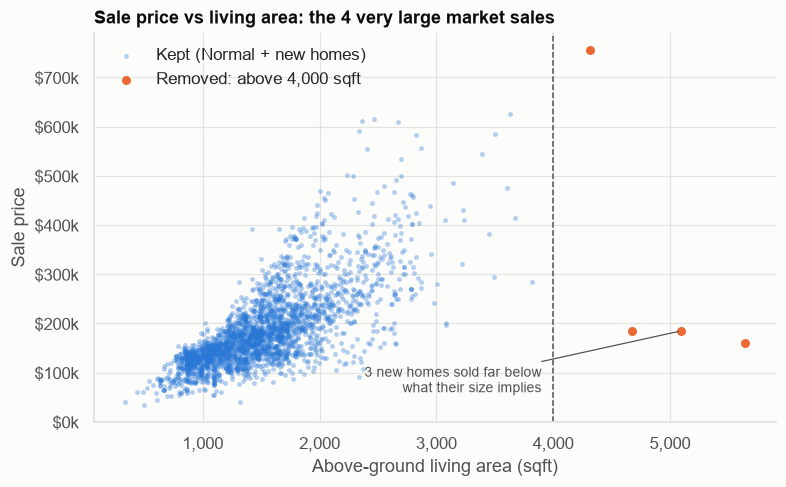

In [23]:
plot_df = df.loc[market]
fig, ax = plt.subplots(figsize=(8, 4.6))
kept = plot_df["Gr Liv Area"] <= 4000
ax.scatter(plot_df.loc[kept, "Gr Liv Area"], plot_df.loc[kept, "SalePrice"], s=10, alpha=0.35,
           color=COLORS["blue"], linewidths=0, label="Kept (Normal + new homes)")
ax.scatter(plot_df.loc[~kept, "Gr Liv Area"], plot_df.loc[~kept, "SalePrice"], s=55,
           color=COLORS["orange"], edgecolor=COLORS["surface"], linewidth=1.5, label="Removed: above 4,000 sqft")
ax.axvline(4000, color=COLORS["text2"], lw=1, ls="--")
ax.annotate("3 new homes sold far below\nwhat their size implies", xy=(5100, 185000), xytext=(3900, 60000),
            fontsize=9, color=COLORS["text2"], ha="right", arrowprops=dict(arrowstyle="-", color=COLORS["text2"], lw=0.8))
ax.yaxis.set_major_formatter(USD)
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_xlabel("Above-ground living area (sqft)")
ax.set_ylabel("Sale price")
ax.set_title("Sale price vs living area: the 4 very large market sales")
ax.legend(frameon=False, loc="upper left")
save_fig(fig, "01_large_house_outliers")
plt.show()

In [24]:
sample = df.loc[market & ~large].copy()
sample["is_new_home"] = sample["Sale Condition"].eq("Partial").astype(int)
log("1.5", "Non-market sales (Abnorml, Family, Alloca, AdjLand)", (~market).sum(), "Excluded from the analysis sample",
    "Not open-market prices (e.g. foreclosure-type sales ~8% below comparable Normal sales)")
log("1.5", "Houses above 4,000 sqft", (market & large).sum(), "Excluded from the analysis sample",
    "3 incomplete-looking new-home sales, 1 luxury home with no comparables; model valid up to 4,000 sqft")
print(f"Analysis sample: {len(sample):,} sales ({sample['is_new_home'].sum()} new homes, "
      f"{(1 - sample['is_new_home']).sum():,} normal resales)")

Analysis sample: 2,629 sales (238 new homes, 2,391 normal resales)


### 1.6 Lot Frontage: drop — **[REVIEW PENDING]**

> **Status: provisional decision, to be reviewed with the author.** The recommended option is applied through a single switch, `DROP_LOT_FRONTAGE`, so the decision can be reversed in one line after the review. Points to discuss:
> 1. What we give up: the analysis can say nothing about street frontage itself. The lot is still described by `Lot Area` and `Lot Config`.
> 2. The alternative: impute with the neighborhood median plus a "was missing" flag.
> 3. The model-based check in Section 2 (cross-validated error with and without the variable), as part of the variable-selection step.

Evidence on the analysis sample:

In [25]:
lf_data = sample.dropna(subset=["Lot Frontage", "Lot Area", "Year Built"])
X_lf = sm.add_constant(np.column_stack([np.log(lf_data["Gr Liv Area"]), lf_data["Overall Qual"],
                                        lf_data["Year Built"], np.log(lf_data["Lot Area"])]))
resid_lf = sm.OLS(np.log(lf_data["SalePrice"]), X_lf).fit().resid
lf_evidence = pd.Series({
    "share missing": sample["Lot Frontage"].isna().mean(),
    "Spearman: Lot Frontage vs price": sample["Lot Frontage"].corr(sample["SalePrice"], method="spearman"),
    "Spearman: Lot Area vs price": sample["Lot Area"].corr(sample["SalePrice"], method="spearman"),
    "Spearman: Lot Frontage vs Lot Area": sample["Lot Frontage"].corr(sample["Lot Area"], method="spearman"),
    "Spearman: Lot Frontage vs price left unexplained by size, quality, age and lot area":
        lf_data["Lot Frontage"].corr(resid_lf, method="spearman"),
}).round(3)
lf_evidence.to_frame("value")

,value
share missing,0.172
Spearman: Lot Frontage vs price,0.416
Spearman: Lot Area vs price,0.438
Spearman: Lot Frontage vs Lot Area,0.671
"Spearman: Lot Frontage vs price left unexplained by size, quality, age and lot area",0.026


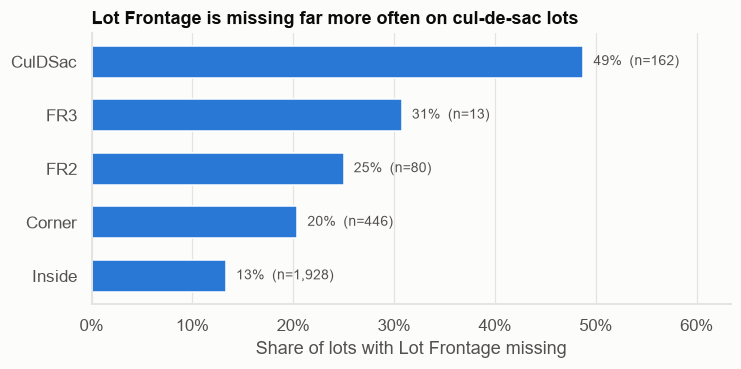

In [26]:
miss = sample.groupby("Lot Config")["Lot Frontage"].agg(share_missing=lambda s: s.isna().mean(), n="size").sort_values("share_missing")
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.barh(miss.index, miss["share_missing"], color=COLORS["blue"], height=0.6)
for y, (v, n) in enumerate(zip(miss["share_missing"], miss["n"])):
    ax.text(v + 0.01, y, f"{v:.0%}  (n={n:,})", va="center", fontsize=9, color=COLORS["text2"])
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
ax.set_xlim(0, miss["share_missing"].max() * 1.3)
ax.set_xlabel("Share of lots with Lot Frontage missing")
ax.set_title("Lot Frontage is missing far more often on cul-de-sac lots")
ax.grid(axis="y", visible=False)
plt.show()

**Reading.** Lot Frontage tracks Lot Area closely, and once size, quality, age and lot area are accounted for, almost no relationship with price remains. Its gaps are **not random**: they are concentrated on cul-de-sac lots, where frontage is curved and hard to measure. Imputing it would invent values exactly where the measurement makes least sense.

In [27]:
DROP_LOT_FRONTAGE = True   # [REVIEW PENDING] set to False to keep it (it would then be imputed in the pipeline)

if DROP_LOT_FRONTAGE:
    sample = sample.drop(columns="Lot Frontage")
    log("1.6", "Lot Frontage (17% missing, not at random)", len(sample), "Column dropped [REVIEW PENDING]",
        "No price information beyond Lot Area; gaps concentrated on cul-de-sac lots")

### 1.7 Remaining missing values and summary

What is still missing in the analysis sample is a **real** gap, except `Garage Yr Blt` on houses without a garage. These values are imputed inside the model pipeline, which is fitted on training data only, in Section 3. `Garage Yr Blt` will most likely be removed in Section 2 because it largely duplicates `Year Built`.

In [28]:
missing = sample.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False).to_frame("missing")
missing["% of sample"] = (100 * missing["missing"] / len(sample)).round(2)
missing["note"] = ""
no_garage = sample["Garage Type"].eq(ABSENT)
if "Garage Yr Blt" in missing.index:
    missing.loc["Garage Yr Blt", "note"] = f"{(sample['Garage Yr Blt'].isna() & no_garage).sum()} of them have no garage (no year applies)"
sample.to_csv(PROCESSED_DIR / "analysis_sample.csv", index=False)
missing

,missing,% of sample,note
Garage Yr Blt,120,4.56,119 of them have no garage (no year applies)
Lot Area,30,1.14,
Mas Vnr Type,29,1.10,
Mas Vnr Area,22,0.84,
Year Built,8,0.30,
MS Zoning,5,0.19,
Bsmt Exposure,3,0.11,
BsmtFin Type 2,1,0.04,
Electrical,1,0.04,
Garage Finish,1,0.04,


In [29]:
quality_log = pd.DataFrame(QUALITY_LOG)
quality_log.to_csv(PROCESSED_DIR / "data_quality_log.csv", index=False)
print(f"Raw file: {len(raw):,} rows -> cleaned (all valid sales): {len(df):,} -> analysis sample: {len(sample):,}")
print(f"Saved to {PROCESSED_DIR.relative_to(ROOT)}: clean_all_sales.csv, analysis_sample.csv, data_quality_log.csv")
quality_log

Raw file: 2,963 rows -> cleaned (all valid sales): 2,901 -> analysis sample: 2,629
Saved to data\processed: clean_all_sales.csv, analysis_sample.csv, data_quality_log.csv


,step,issue,rows_affected,action,rationale
0,1,Empty rows,3,Dropped,"No PID, no price, >90% of fields blank"
1,2,SalePrice stored as text,30,"Removed '$' and ',' and converted to number",Formatting problem only; the amount is valid
2,2,Lot Area with units text ('sqft'),20,"Removed text, kept the number",Formatting problem only
3,2,Lot Area recorded in square meters,30,Multiplied by 10.764 and rounded,"Only decimal values in a whole-number column, ..."
4,2,Lot Area equal to zero,20,Set to missing (imputed later in the pipeline),A lot cannot have zero area
5,3,Category labels with extra spaces / wrong case...,2571,Mapped to the dictionary code,Same category written differently; would other...
6,4,Exact duplicate rows,19,Dropped (kept first),Same sale recorded twice
7,4,Same sale recorded twice with small difference...,11,"Kept one record: valid price, fewest missing v...","Differences <0.1% (about $100 / 1 sqft), so th..."
8,5,Gr Liv Area missing,10,Computed as 1st + 2nd + low-quality floor area,"Exact identity, verified with 0 mismatches in ..."
9,6,SalePrice missing,19,Dropped,The target is never invented; see the agreed d...


**Summary of Section 1.** Every issue listed in the audit was either repaired with same-row evidence (formats, units, labels, years, neighborhoods, living area), removed because it could not be trusted (invalid prices, duplicates, impossible sale dates), or encoded explicitly ("Absent" features). The re-audit confirms that every check returns zero. Two scope decisions, non-market sales and very large houses, define the analysis sample. One decision, dropping Lot Frontage, is pending review with the author.

## 2. Exploratory data analysis

*To be developed (Phase 2).*

## 3. Q1 — Price range model

*To be developed (Phase 3).*

## 4. Q2 — Price drivers

*To be developed (Phase 4).*

## 5. Q3 — Improvement return on investment

*To be developed (Phase 5).*

## 6. Q4 — Market segmentation

*To be developed (Phase 6).*

## 7. Conclusions, limitations and next steps

*To be developed (Phase 7).*